# Robustness of metrics to distance metric


In [1]:
import os
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

import numpy as np
import pandas as pd
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
import glob
import sklearn
import matplotlib.pyplot as plt
import json
import re
import ast
import math
import colorcet as cc
import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

In [2]:
import rpy2.robjects as robjects
from rpy2.robjects import conversion, default_converter
from rpy2.robjects.pandas2ri import converter as pandas_converter

In [3]:
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')

from analysis_helpers import *

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [4]:
ordered_metrics = [
    'CCENT', 'HOMO', 'JACC', 'PURITY', 'NMIF', 'ARIF', 'BKNN', 'FKNN', 'MCC', 'F1', 'NNMAP', 'CNENT', 'OCS', 'KSIM', 'CLISI',  # Cluster-as-prediction and knn
    'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 'VI', 'FMI', # Cluster-label similarity
    'GC', 'CASW',
    'COMP', 'PPTPC', 'PSTDB', # Joint bio&batch
    'CLUSTASW', 'CLUSTCH', 'CLUSTDBI', 'MODULARITY', 'COMPACT', 'SEPARATION', # Independent cluster metrics
    'AGREE', 'RKNN', 'SCGRAPH', 'SCGRAPHM', 'SCGRAPHP',
    'BASW', 'BCENT', 'CRE', 'BATCHARI', 'BRAS', 'ALIGN', 'MIX', 'ILISI', 'BNENT', 'KLDIV', 'ADGBD', 'KBETALL', 'CILISI', 'KBET'
]

In [5]:
def compute_w_across_integrations(df):
    rank_df = df.copy()
    rank_df['Rank'] = rank_df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='average')
    
    results = []
    for metric, group in rank_df.groupby('Metric'):
        pivot = group.pivot_table(index='Integration', columns='dist_metric', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)

        def compute_T(ranks_series):
            tie_counts = ranks_series.value_counts()
            tied = tie_counts[tie_counts > 1]
            return (tied**3 - tied).sum()

        sum_T = pivot.apply(compute_T, axis=0).sum()

        # Kendall's W with tie correction
        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T

        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

In [6]:
def compute_tau_across_integrations(df):
    with conversion.localconverter(default_converter + pandas_converter):
        robjects.globalenv['df_sub'] = conversion.py2rpy(df[['Metric', 'Integration', 'dist_metric', "Value"]])
        w = robjects.r('''
library(dplyr)
library(tidyr)
library(purrr)

all_tau <- df_sub %>%
  group_by(Metric) %>%
  group_modify(~ {
    sub <- .x
    dist_metric <- unique(sub$dist_metric)
    combos <- combn(dist_metric, 2, simplify = FALSE)
    
    map_dfr(combos, function(pair) {
      c1 <- pair[1]
      c2 <- pair[2]
      
      common_integrations <- intersect(
        sub$Integration[sub$dist_metric == c1],
        sub$Integration[sub$dist_metric == c2]
      )
      
      sub1 <- sub %>%
        filter(Integration %in% common_integrations, dist_metric == c1) %>%
        arrange(Integration) %>%
        mutate(Rank = rank(Value))
      
      sub2 <- sub %>%
        filter(Integration %in% common_integrations, dist_metric == c2) %>%
        arrange(Integration) %>%
        mutate(Rank = rank(Value))

      tau_result <- cor.test(sub1$Rank, sub2$Rank, method = "kendall")
      
      tibble(
        Dist1   = c1,
        Dist2   = c2,
        tau     = tau_result$estimate,
        p_value = tau_result$p.value
      )
    })
  }) %>%
  ungroup()

all_tau
    ''')
        return conversion.rpy2py(w)

## Step 1: Collect all the data from the eight different datasets
### Cellranger versions

In [7]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/cellranger_versions/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/cellranger_versions_rescue/metrics/all-metrics.csv')

df = pd.concat([df, df2])

df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})

df['dist_metric'] = df['Params'].apply(lambda x: eval(x)['metric'])
df = df.drop_duplicates(subset=['Metric', 'Integration', 'dist_metric'], keep='last')

In [ ]:
label_order = ['euclidean', 'l1', 'cosine']
df['dist_metric'] = pd.Categorical(df['dist_metric'], categories=label_order, ordered=True)

df['Rank'] = df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df[df['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='dist_metric',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('Clustering algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [8]:
w_results_1 = compute_w_across_integrations(df)
w_results_1['Dataset'] = "cellranger_versions"
w_results_1

,Metric,Kendall_W,Dataset
0,ADGBD,0.995769,cellranger_versions
1,AGREE,0.998298,cellranger_versions
2,ALIGN,0.995283,cellranger_versions
3,AMI,0.956886,cellranger_versions
4,ARI,0.952801,cellranger_versions
5,ARIF,0.898620,cellranger_versions
6,AWC,0.957567,cellranger_versions
7,BAMI,0.979209,cellranger_versions
8,BARI,0.971136,cellranger_versions
9,BASW,0.990128,cellranger_versions


In [9]:
tau_results_1 = compute_tau_across_integrations(df)
tau_results_1['Dataset'] = 'cellranger_versions'
tau_results_1

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: 
Attaching package: ‘dplyr’

  
R callback write-console: The following objects are masked from ‘package:stats’:

    filter, lag

  
R callback write-console: The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

  
R callback write-console: In addition:   
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  


,Metric,Dist1,Dist2,tau,p_value,Dataset
1,ADGBD,l1,euclidean,0.985775,-3.108624e-15,cellranger_versions
2,ADGBD,l1,cosine,0.943101,-3.108624e-15,cellranger_versions
3,ADGBD,euclidean,cosine,0.957326,-3.108624e-15,cellranger_versions
4,AGREE,euclidean,l1,0.980085,-3.108624e-15,cellranger_versions
5,AGREE,euclidean,cosine,0.968706,-3.108624e-15,cellranger_versions
...,...,...,...,...,...,...
167,VI,euclidean,l1,0.848399,6.708770e-14,cellranger_versions
168,VI,cosine,l1,0.843528,-3.108624e-15,cellranger_versions
169,VM,euclidean,cosine,0.791459,2.738468e-12,cellranger_versions
170,VM,euclidean,l1,0.811388,7.691014e-13,cellranger_versions


In [10]:
df_1 = df.copy()

### NeurIPS BMMC

In [11]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/neurips_bmmc/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/neurips_bmmc_resuce/metrics/all-metrics.csv')

df = pd.concat([df, df2])
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df['dist_metric'] = df['Params'].apply(lambda x: eval(x)['metric'])
df = df.drop_duplicates(subset=['Metric', 'Integration', 'dist_metric'], keep='last')

In [ ]:
label_order = ['euclidean', 'l1', 'cosine']
df['dist_metric'] = pd.Categorical(df['dist_metric'], categories=label_order, ordered=True)

df['Rank'] = df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df[df['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='dist_metric',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('Clustering algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [12]:
w_results_2 = compute_w_across_integrations(df)
w_results_2['Dataset'] = "neurips_bmmc"
w_results_2

,Metric,Kendall_W,Dataset
0,ADGBD,0.990359,neurips_bmmc
1,AGREE,0.997313,neurips_bmmc
2,ALIGN,0.988462,neurips_bmmc
3,AMI,0.987461,neurips_bmmc
4,ARI,0.954481,neurips_bmmc
5,ARIF,0.953374,neurips_bmmc
6,AWC,0.960381,neurips_bmmc
7,BAMI,0.996417,neurips_bmmc
8,BARI,0.978874,neurips_bmmc
9,BASW,0.984195,neurips_bmmc


In [13]:
tau_results_2 = compute_tau_across_integrations(df)
tau_results_2['Dataset'] = 'neurips_bmmc'
tau_results_2

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1:   
R callback write-console: In cor.test.default(sub1$Rank, sub2$Rank, method = "kendall") :  
R callback write-console: 
   
R callback write-console:  Cannot compute exact p-value with ties
  
R callback write-console: 2:   
R callback write-console: In cor.test.default(sub1$Rank, sub2$Rank, method = "kendall") :  
R callback write-console: 
   
R callback write-console:  Cannot compute exact p-value with ties
  
R callback write-console: 3:   
R callback write-console: In cor.test.default(sub1$Rank, sub2$Rank, method = "kendall") :  
R call

,Metric,Dist1,Dist2,tau,p_value,Dataset
1,ADGBD,euclidean,l1,0.975976,4.218847e-15,neurips_bmmc
2,ADGBD,euclidean,cosine,0.918919,4.218847e-15,neurips_bmmc
3,ADGBD,l1,cosine,0.918919,4.218847e-15,neurips_bmmc
4,AGREE,l1,euclidean,0.960961,4.218847e-15,neurips_bmmc
5,AGREE,l1,cosine,0.951952,4.218847e-15,neurips_bmmc
...,...,...,...,...,...,...
176,VI,euclidean,l1,0.834835,4.218847e-15,neurips_bmmc
177,VI,cosine,l1,0.852853,4.218847e-15,neurips_bmmc
178,VM,euclidean,cosine,0.930931,4.218847e-15,neurips_bmmc
179,VM,euclidean,l1,0.900901,4.218847e-15,neurips_bmmc


In [14]:
df_2 = df.copy()

### Human pancreas

In [15]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/human_pancreas/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/human_pancreas_rescue/metrics/all-metrics.csv')

df = pd.concat([df, df2])
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df['dist_metric'] = df['Params'].apply(lambda x: eval(x)['metric'])
df = df.drop_duplicates(subset=['Metric', 'Integration', 'dist_metric'], keep='last')

In [ ]:
label_order = ['euclidean', 'l1', 'cosine']
df['dist_metric'] = pd.Categorical(df['dist_metric'], categories=label_order, ordered=True)

df['Rank'] = df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df[df['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='dist_metric',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('Clustering algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [16]:
w_results_3 = compute_w_across_integrations(df)
w_results_3['Dataset'] = "human_pancreas"
w_results_3

,Metric,Kendall_W,Dataset
0,ADGBD,0.995861,human_pancreas
1,AGREE,0.994557,human_pancreas
2,ALIGN,0.991678,human_pancreas
3,AMI,0.993612,human_pancreas
4,ARI,0.991903,human_pancreas
5,ARIF,0.991183,human_pancreas
6,AWC,0.992488,human_pancreas
7,BAMI,0.991858,human_pancreas
8,BARI,0.990778,human_pancreas
9,BASW,0.971930,human_pancreas


In [17]:
tau_results_3 = compute_tau_across_integrations(df)
tau_results_3['Dataset'] = 'human_pancreas'
tau_results_3

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: There were 24 warnings (use warnings() to see them)  
R callback write-console: 
  


,Metric,Dist1,Dist2,tau,p_value,Dataset
1,ADGBD,euclidean,cosine,0.951417,-4.440892e-16,human_pancreas
2,ADGBD,euclidean,l1,0.983806,-4.440892e-16,human_pancreas
3,ADGBD,cosine,l1,0.951417,-4.440892e-16,human_pancreas
4,AGREE,euclidean,l1,0.956815,-4.440892e-16,human_pancreas
5,AGREE,euclidean,cosine,0.964912,-4.440892e-16,human_pancreas
...,...,...,...,...,...,...
176,VI,euclidean,l1,0.981107,-4.440892e-16,human_pancreas
177,VI,cosine,l1,0.935223,-4.440892e-16,human_pancreas
178,VM,euclidean,cosine,0.943320,-4.440892e-16,human_pancreas
179,VM,euclidean,l1,0.983806,-4.440892e-16,human_pancreas


In [18]:
df_3 = df.copy()

### Seurat PBMC

In [19]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/seurat_pbmc/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/seurat_pbmc_rescue/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/seurat_pbmc_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3])
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]

df['dist_metric'] = df['Params'].apply(lambda x: eval(x)['metric'])
df = df.drop_duplicates(subset=['Metric', 'Integration', 'dist_metric'], keep='last')

In [ ]:
label_order = ['euclidean', 'l1', 'cosine']
df['dist_metric'] = pd.Categorical(df['dist_metric'], categories=label_order, ordered=True)

df['Rank'] = df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df[df['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='dist_metric',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('Clustering algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [20]:
w_results_4 = compute_w_across_integrations(df)
w_results_4['Dataset'] = "seurat_pbmc"
w_results_4

,Metric,Kendall_W,Dataset
0,ADGBD,0.989358,seurat_pbmc
1,AGREE,0.996312,seurat_pbmc
2,ALIGN,0.995364,seurat_pbmc
3,AMI,0.988146,seurat_pbmc
4,ARI,0.974606,seurat_pbmc
5,ARIF,0.965382,seurat_pbmc
6,AWC,0.966229,seurat_pbmc
7,BAMI,0.991992,seurat_pbmc
8,BARI,0.990938,seurat_pbmc
9,BASW,0.980085,seurat_pbmc


In [21]:
tau_results_4 = compute_tau_across_integrations(df)
tau_results_4['Dataset'] = 'seurat_pbmc'
tau_results_4

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: There were 30 warnings (use warnings() to see them)  
R callback write-console: 
  


,Metric,Dist1,Dist2,tau,p_value,Dataset
1,ADGBD,euclidean,cosine,0.927928,4.218847e-15,seurat_pbmc
2,ADGBD,euclidean,l1,0.966967,4.218847e-15,seurat_pbmc
3,ADGBD,cosine,l1,0.912913,4.218847e-15,seurat_pbmc
4,AGREE,euclidean,cosine,0.960961,4.218847e-15,seurat_pbmc
5,AGREE,euclidean,l1,0.969970,4.218847e-15,seurat_pbmc
...,...,...,...,...,...,...
167,VI,euclidean,l1,0.843844,4.218847e-15,seurat_pbmc
168,VI,cosine,l1,0.864865,4.218847e-15,seurat_pbmc
169,VM,euclidean,cosine,0.909910,4.218847e-15,seurat_pbmc
170,VM,euclidean,l1,0.906907,4.218847e-15,seurat_pbmc


In [22]:
df_4 = df.copy()

### Human PBMC seq techs

In [23]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/human_pbmc_seq_techs/metrics/all-metrics.csv')

df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df['dist_metric'] = df['Params'].apply(lambda x: eval(x)['metric'])
df = df.drop_duplicates(subset=['Metric', 'Integration', 'dist_metric'], keep='last')

In [ ]:
label_order = ['euclidean', 'l1', 'cosine']
df['dist_metric'] = pd.Categorical(df['dist_metric'], categories=label_order, ordered=True)

df['Rank'] = df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df[df['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='dist_metric',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('Clustering algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [24]:
w_results_5 = compute_w_across_integrations(df)
w_results_5['Dataset'] = "human_pbmc_seq_techs"
w_results_5

,Metric,Kendall_W,Dataset
0,ADGBD,0.982726,human_pbmc_seq_techs
1,AGREE,0.991248,human_pbmc_seq_techs
2,ALIGN,0.990276,human_pbmc_seq_techs
3,AMI,0.992106,human_pbmc_seq_techs
4,ARI,0.993022,human_pbmc_seq_techs
5,ARIF,0.991649,human_pbmc_seq_techs
6,AWC,0.992907,human_pbmc_seq_techs
7,BAMI,0.994394,human_pbmc_seq_techs
8,BARI,0.992906,human_pbmc_seq_techs
9,BASW,0.954011,human_pbmc_seq_techs


In [25]:
tau_results_5 = compute_tau_across_integrations(df)
tau_results_5['Dataset'] = 'human_pbmc_seq_techs'
tau_results_5

R callback write-console: In addition:   
R callback write-console: There were 44 warnings (use warnings() to see them)  
R callback write-console: 
  


,Metric,Dist1,Dist2,tau,p_value,Dataset
1,ADGBD,euclidean,cosine,0.917460,-1.776357e-15,human_pbmc_seq_techs
2,ADGBD,euclidean,l1,0.952381,-1.776357e-15,human_pbmc_seq_techs
3,ADGBD,cosine,l1,0.895238,-1.776357e-15,human_pbmc_seq_techs
4,AGREE,l1,euclidean,0.946032,-1.776357e-15,human_pbmc_seq_techs
5,AGREE,l1,cosine,0.898413,-1.776357e-15,human_pbmc_seq_techs
...,...,...,...,...,...,...
176,VI,euclidean,l1,0.949206,-1.776357e-15,human_pbmc_seq_techs
177,VI,cosine,l1,0.914286,-1.776357e-15,human_pbmc_seq_techs
178,VM,euclidean,cosine,0.930159,-1.776357e-15,human_pbmc_seq_techs
179,VM,euclidean,l1,0.933333,-1.776357e-15,human_pbmc_seq_techs


In [26]:
df_5 = df.copy()

### scIB sim1

In [27]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/scib_sim1/metrics/all-metrics.csv')

df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df['dist_metric'] = df['Params'].apply(lambda x: eval(x)['metric'])
df = df.drop_duplicates(subset=['Metric', 'Integration', 'dist_metric'], keep='last')

In [ ]:
label_order = ['euclidean', 'l1', 'cosine']
df['dist_metric'] = pd.Categorical(df['dist_metric'], categories=label_order, ordered=True)

df['Rank'] = df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df[df['Metric'] == metric]

    sns.lineplot(
        data=subset,
        x='dist_metric',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('Clustering algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [28]:
w_results_6 = compute_w_across_integrations(df)
w_results_6['Dataset'] = "scib_sim1"
w_results_6

,Metric,Kendall_W,Dataset
0,ADGBD,0.992546,scib_sim1
1,AGREE,0.985582,scib_sim1
2,ALIGN,0.996823,scib_sim1
3,AMI,0.985051,scib_sim1
4,ARI,0.982986,scib_sim1
5,ARIF,0.991481,scib_sim1
6,AWC,0.982986,scib_sim1
7,BAMI,0.994879,scib_sim1
8,BARI,0.993641,scib_sim1
9,BASW,0.986233,scib_sim1


In [29]:
tau_results_6 = compute_tau_across_integrations(df)
tau_results_6['Dataset'] = 'scib_sim1'
tau_results_6

R callback write-console: In addition:   
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  


,Metric,Dist1,Dist2,tau,p_value,Dataset
1,ADGBD,euclidean,l1,0.970737,6.135052e-15,scib_sim1
2,ADGBD,euclidean,cosine,0.931313,7.560607e-14,scib_sim1
3,ADGBD,l1,cosine,0.942483,3.616827e-14,scib_sim1
4,AGREE,l1,euclidean,0.947581,-1.332268e-15,scib_sim1
5,AGREE,l1,cosine,0.891129,-1.332268e-15,scib_sim1
...,...,...,...,...,...,...
176,VI,euclidean,cosine,0.920492,9.314485e-13,scib_sim1
177,VI,l1,cosine,0.916250,1.182752e-12,scib_sim1
178,VM,euclidean,l1,0.991453,1.932305e-14,scib_sim1
179,VM,euclidean,cosine,0.933218,4.520458e-13,scib_sim1


In [30]:
df_6 = df.copy()

### NHP cerebellum

In [31]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/nph_cerebellum/metrics/all-metrics.csv')

df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df['dist_metric'] = df['Params'].apply(lambda x: eval(x)['metric'])
df = df.drop_duplicates(subset=['Metric', 'Integration', 'dist_metric'], keep='last')

In [ ]:
label_order = ['euclidean', 'l1', 'cosine']
df['dist_metric'] = pd.Categorical(df['dist_metric'], categories=label_order, ordered=True)

df['Rank'] = df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df[df['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='dist_metric',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('Clustering algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [32]:
w_results_7 = compute_w_across_integrations(df)
w_results_7['Dataset'] = "nhp_cerebellum"
w_results_7

,Metric,Kendall_W,Dataset
0,ADGBD,0.935753,nhp_cerebellum
1,AGREE,0.991577,nhp_cerebellum
2,ALIGN,0.993011,nhp_cerebellum
3,AMI,0.933961,nhp_cerebellum
4,ARI,0.927061,nhp_cerebellum
5,ARIF,0.828853,nhp_cerebellum
6,AWC,0.909767,nhp_cerebellum
7,BAMI,0.952599,nhp_cerebellum
8,BARI,0.956362,nhp_cerebellum
9,BASW,0.952419,nhp_cerebellum


In [33]:
tau_results_7 = compute_tau_across_integrations(df)
tau_results_7['Dataset'] = 'nhp_cerebellum'
tau_results_7

R callback write-console: In addition:   
R callback write-console: There were 12 warnings (use warnings() to see them)  
R callback write-console: 
  


,Metric,Dist1,Dist2,tau,p_value,Dataset
1,ADGBD,euclidean,cosine,0.759140,7.361667e-12,nhp_cerebellum
2,ADGBD,euclidean,l1,0.969892,-1.776357e-15,nhp_cerebellum
3,ADGBD,cosine,l1,0.754839,1.079337e-11,nhp_cerebellum
4,AGREE,cosine,euclidean,0.935484,-1.776357e-15,nhp_cerebellum
5,AGREE,cosine,l1,0.909677,-1.776357e-15,nhp_cerebellum
...,...,...,...,...,...,...
167,VI,euclidean,l1,0.810753,4.041212e-14,nhp_cerebellum
168,VI,cosine,l1,0.677419,4.149616e-09,nhp_cerebellum
169,VM,euclidean,cosine,0.750538,1.572498e-11,nhp_cerebellum
170,VM,euclidean,l1,0.815054,2.420286e-14,nhp_cerebellum


In [34]:
df_7 = df.copy()

### Mouse mammary

In [35]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/distance_ablation/mouse_mammary/metrics/all-metrics.csv')

df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df['dist_metric'] = df['Params'].apply(lambda x: eval(x)['metric'])
df = df.drop_duplicates(subset=['Metric', 'Integration', 'dist_metric'], keep='last')

/tmp/ipykernel_1410092/765526673.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df['Rank'] = df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='min')


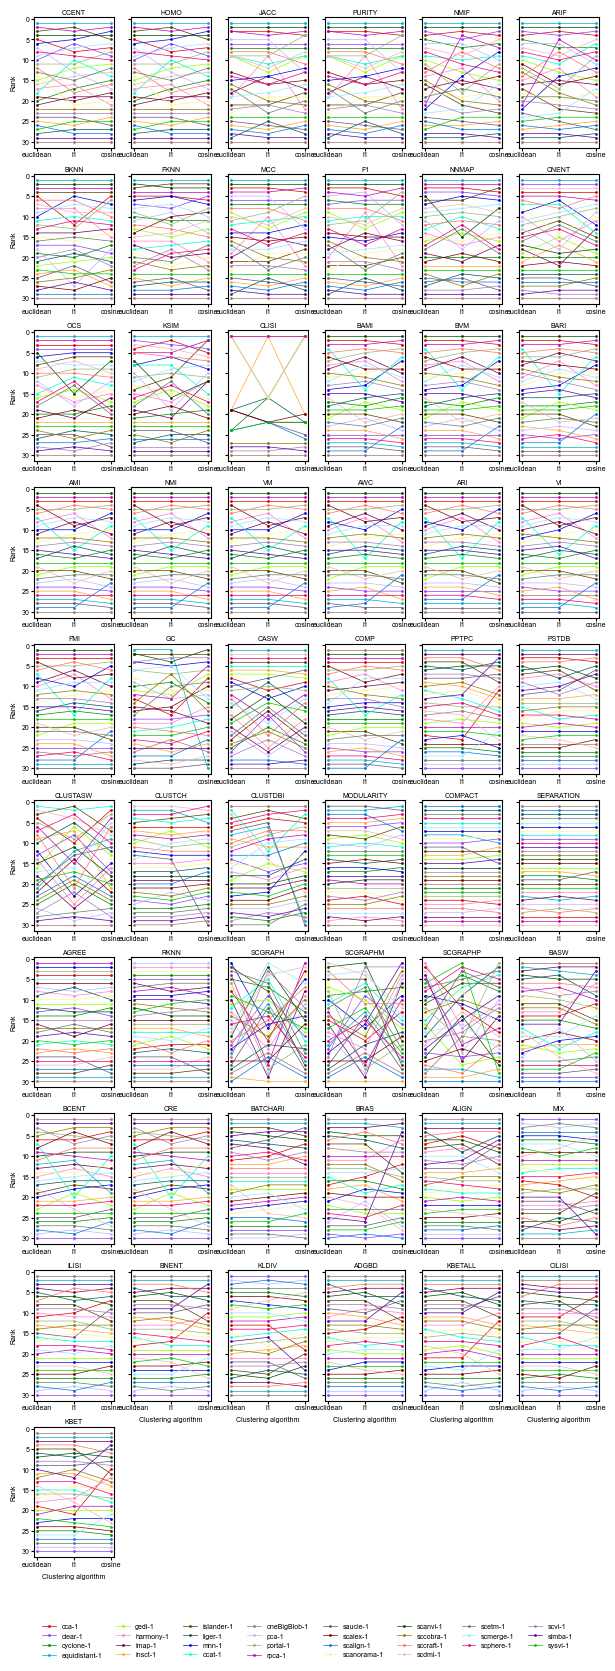

In [41]:
label_order = ['euclidean', 'l1', 'cosine']
df['dist_metric'] = pd.Categorical(df['dist_metric'], categories=label_order, ordered=True)

df['Rank'] = df.groupby(['Metric', 'dist_metric'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df[df['Metric'] == metric]

    sns.lineplot(
        data=subset,
        x='dist_metric',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('Clustering algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [36]:
w_results_8 = compute_w_across_integrations(df)
w_results_8['Dataset'] = "mouse_mammary"
w_results_8

,Metric,Kendall_W,Dataset
0,ADGBD,0.985762,mouse_mammary
1,AGREE,0.994067,mouse_mammary
2,ALIGN,0.982796,mouse_mammary
3,AMI,0.978149,mouse_mammary
4,ARI,0.974886,mouse_mammary
5,ARIF,0.935039,mouse_mammary
6,AWC,0.972315,mouse_mammary
7,BAMI,0.968162,mouse_mammary
8,BARI,0.967964,mouse_mammary
9,BASW,0.946212,mouse_mammary


In [37]:
tau_results_8 = compute_tau_across_integrations(df)
tau_results_8['Dataset'] = 'mouse_mammary'
tau_results_8

R callback write-console: In addition:   
R callback write-console: There were 24 warnings (use warnings() to see them)  
R callback write-console: 
  


,Metric,Dist1,Dist2,tau,p_value,Dataset
1,ADGBD,euclidean,l1,0.944828,1.110223e-15,mouse_mammary
2,ADGBD,euclidean,cosine,0.885057,1.110223e-15,mouse_mammary
3,ADGBD,l1,cosine,0.912644,1.110223e-15,mouse_mammary
4,AGREE,l1,euclidean,0.958621,1.110223e-15,mouse_mammary
5,AGREE,l1,cosine,0.917241,1.110223e-15,mouse_mammary
...,...,...,...,...,...,...
167,VI,euclidean,cosine,0.880460,1.110223e-15,mouse_mammary
168,VI,l1,cosine,0.848276,2.442491e-15,mouse_mammary
169,VM,euclidean,l1,0.894253,1.110223e-15,mouse_mammary
170,VM,euclidean,cosine,0.889655,1.110223e-15,mouse_mammary


In [38]:
df_8 = df.copy()

## Plot Kendall's W and $\tau$

In [39]:
w_results = pd.concat([w_results_1, w_results_2, w_results_3, w_results_4, w_results_5, w_results_6, w_results_7, w_results_8])
w_results.reset_index(drop=True, inplace=True)
w_results = w_results[w_results['Metric'] != 'CLUSTACC']

### Pairwise Kendall's $\tau$ between distance metrics

In [40]:
tau_results = pd.concat([tau_results_1, tau_results_2, tau_results_3, tau_results_4, tau_results_5, tau_results_6, tau_results_7, tau_results_8])
tau_results.reset_index(drop=True, inplace=True)

dist_order = {"euclidean": 0, "l1": 1, "cosine": 2}
dist_matrix = tau_results[["Dist1", "Dist2"]].map(dist_order.get).to_numpy()
sort_indices = np.argsort(dist_matrix, axis=1)
sorted_distances = np.take_along_axis(
    tau_results[["Dist1", "Dist2"]].to_numpy(), sort_indices, axis=1
)
tau_results[["Dist1", "Dist2"]] = sorted_distances

In [41]:
taus = tau_results.groupby(['Dist1', 'Dist2'])['tau'].apply(list)

In [42]:
per_metric_tau = tau_results.groupby(['Metric', 'Dist1', 'Dist2'])['tau'].mean().reset_index().sort_values(['Metric', "Dist1", 'Dist2'])
per_metric_tau['comparison'] = per_metric_tau['Dist1'] + '_' + per_metric_tau['Dist2']
per_metric_tau.pivot(index='Metric', columns='comparison', values='tau')[['euclidean_l1', 'euclidean_cosine', 'l1_cosine']].to_csv('../results/spreadsheets/distance_ablation_per_metric_taus.csv')

/tmp/ipykernel_3764326/3547886222.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


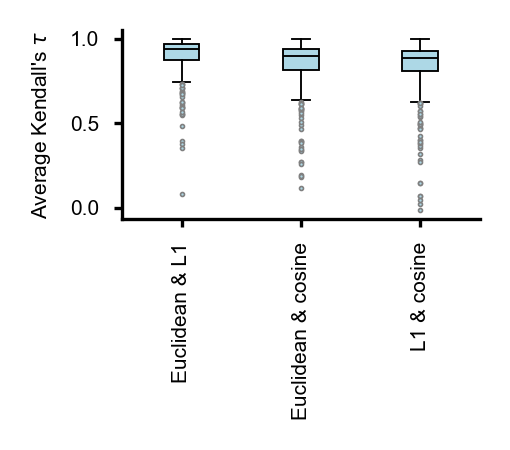

In [43]:
order = ['Euclidean & L1', 'Euclidean & cosine', 'L1 & cosine']
boxplot_data = [
    taus['euclidean', 'l1'],
    taus['euclidean', 'cosine'],
    taus['l1', 'cosine']
]
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(1.8, 1.6))

    ax.boxplot(
        boxplot_data, 
        labels=order, 
        patch_artist=True,  # Allows filling the boxes with color
        boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
        medianprops=dict(color="black", linewidth=.45),
        whiskerprops=dict(color="black", linewidth=.45),
        capprops=dict(color="black", linewidth=.45),
        flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
    )
    ax.tick_params(axis='both', labelsize=5, length=2)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.set_ylabel("Average Kendall's $\\tau$", fontsize=5)
    plt.xticks(rotation=90, fontsize=5)
    plt.tight_layout()
    # plt.savefig('../publication_figures/clustering_algo_taus.png', dpi=300, bbox_inches='tight')
    plt.show()

In [44]:
tau_results[tau_results.Metric == 'SCGRAPHP'].sort_values(['Dist1', 'Dist2', 'Dataset'])

,Metric,Dist1,Dist2,tau,p_value,Dataset
160,SCGRAPHP,euclidean,cosine,0.627312,1.934972e-09,cellranger_versions
520,SCGRAPHP,euclidean,cosine,0.392713,3.291717e-04,human_pancreas
871,SCGRAPHP,euclidean,cosine,0.196825,9.400773e-02,human_pbmc_seq_techs
1393,SCGRAPHP,euclidean,cosine,0.347126,6.678721e-03,mouse_mammary
340,SCGRAPHP,euclidean,cosine,0.639640,1.391920e-09,neurips_bmmc
1223,SCGRAPHP,euclidean,cosine,0.118280,3.617493e-01,nhp_cerebellum
1051,SCGRAPHP,euclidean,cosine,0.270161,3.020007e-02,scib_sim1
691,SCGRAPHP,euclidean,cosine,0.612613,9.208921e-09,seurat_pbmc
159,SCGRAPHP,euclidean,l1,0.803698,-3.108624e-15,cellranger_versions
519,SCGRAPHP,euclidean,l1,0.765182,1.776357e-15,human_pancreas


### Kendall's W across all metrics

/tmp/ipykernel_3764326/190208150.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


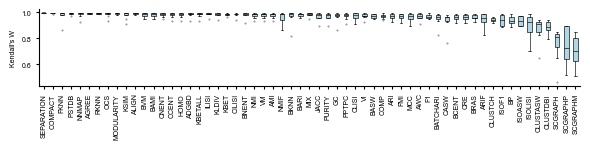

In [45]:
order = w_results.groupby("Metric")["Kendall_W"].median().sort_values(ascending=False).index

# 2. Extract the values for each metric grouped by that sorted order
boxplot_data = [w_results[w_results["Metric"] == metric]["Kendall_W"].values for metric in order]

# 3. Create the boxplot using subplots
fig, ax = plt.subplots(figsize=(6, 1.6))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("Kendall's W", fontsize=5)

plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/distance_metric_W.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_3764326/3702770664.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


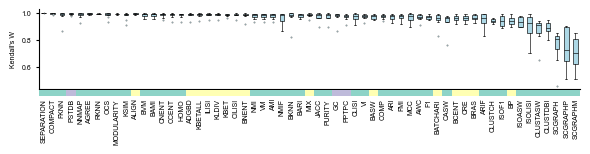

In [46]:
import matplotlib.transforms as mtransforms
from matplotlib.patches import FancyBboxPatch

order = w_results.groupby("Metric")["Kendall_W"].median().sort_values(ascending=False).index
boxplot_data = [w_results[w_results["Metric"] == metric]["Kendall_W"].values for metric in order]
g0 = 'Bioconservation'
g1 = 'Batch correction'
g2 = 'Joint'
# g3 = 'Cell types as clusters'
# g4 = 'Isolated labels & GC'
# g5 = 'Cluster quality 1'
# g6 = 'Joint bioconservation\n& batch correction'
# g7 = 'Finer-grained biology'
# g8 = 'Cluster quality 2'
# h0 = 'Primarily\nbioconservation'
# h1 = 'BASW & SV'
# h2 = 'Clustering metrics'
# h3 = 'PCR & PROBELR'
# h4 = 'Joint bioconservation &\nbatch correction'
# h5 = 'Unique metrics'
# h6 = 'kNN metrics'

metric_to_group = {
    'fmi': g0, 'awc': g0, 'ari': g0, 'vi': g0, 'nmi': g0, 'ami': g0, 'vm':g0, 
    'bari': g0, 'bami': g0, 'bvm': g0, 
    'isoasw': g0, 'gc': g2, 'isof1': g0, 'isolisi': g0,
    'casw': g0, 'cdbi': g0, 'cch': g0, 
    'blogreg': g0, 'flogreg': g0, 
    'clisi': g0, 'fknn': g0, 'ksim': g0, 'ocs': g0, 'nnmap': g0, 'cnent': g0, 
    'cnentropyw': g0, 'bknn': g0, 'f1': g0, 'mcc': g0, 'jacc': g0, 'purity': g0, 
    'ccent': g0, 'homo': g0, 'arif': g0, 'nmif': g0, 
    'clustch': g0, 'clustasw': g0, 'clustdbi': g0, 
    'comp': g0, 'pptpc': g2, 'pstdb': g2, 
    'ldfdiff': g0, 'agree': g0, 'morani': g0, 'rknn': g0, 'ccc': g0, 
    'scgraph': g0, 'corrmse': g0, 'traj': g0, 'scgraphp': g0, 'scgraphm': g0,
    'modularity': g0, 'compact': g0, 'separation': g0,
    'mix': g1, 'align': g1, 'ilisi': g1, 'bnent': g1, 'kldiv': g1,
    'adgbd': g1, 'kbetall': g1, 'cilisi': g1, 'csms': g1, 'kbet': g1,
    'bras': g1, 'embdiv': g1, 'probe': g1, 'batchari': g1, 'pcr': g1,
    'probelr': g1, 'proberf': g1,
    'bp': g1, 'bcent': g1, 'cre': g1,
    'basw': g1, 'sv': g1,
}
group_to_color = {
    g0: '#8dd3c7', g1: '#ffffb3', g2: '#bebada', 
#     g3: '#fb8072', g4: '#80b1d3', g5: '#fdb462', 
#     g6: '#b3de69', g7: '#fccde5', g8: '#d9d9d9',
#     h0: '#E41A1C', h1: '#FFFF33', h2: '#377EB8', 
#     h3: '#984EA3', h4: '#FF7F00', h5: '#4DAF4A',
#     h6: '#A65628'
}

fig, ax = plt.subplots(figsize=(6, 1.1))
ax.boxplot(
    boxplot_data,
    labels=order,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95,
                    markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.tick_params(axis='x', length=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylabel("Kendall's W", fontsize=5)

# Turn off default tick labels — we'll reposition them manually below the color boxes
ax.set_xticklabels([])

plt.tight_layout()
fig.canvas.draw()  # finalize layout before adding patches

# --- sizing in points ---
box_h_pt   = 4    # height of each color box
box_w_pt   = 18   # width of each color box (adjust to taste)
gap_pt     = 0.6    # gap between tick line and box top

# Convert points to display units
dpi        = fig.dpi
pt_to_disp = dpi / 72.0

# Transform: x in data coords, y pinned to axes bottom in display coords
trans = ax.transData

if len(order) > 1:
    x0_disp = ax.transData.transform((1, ax.get_ylim()[0]))[0]
    x1_disp = ax.transData.transform((2, ax.get_ylim()[0]))[0]
    tick_spacing_disp = x1_disp - x0_disp
else:
    tick_spacing_disp = 20 * pt_to_disp

box_w_disp = tick_spacing_disp * 1  # 85% of spacing, leaving a small gap between boxes

for i, metric in enumerate(order):
    tick_x = i + 1
    grp    = metric_to_group.get(metric.lower(), "Unknown")
    color  = group_to_color.get(grp, "gray")

    x_disp, y_disp = ax.transData.transform((tick_x, ax.get_ylim()[0]))

    box_top    = y_disp - gap_pt * pt_to_disp
    box_bottom = box_top - box_h_pt * pt_to_disp
    box_left   = x_disp - box_w_disp / 2
    box_right  = x_disp + box_w_disp / 2

    inv = ax.transAxes.inverted()
    xl, yt = inv.transform((box_left,  box_top))
    xr, yb = inv.transform((box_right, box_bottom))

    rect = FancyBboxPatch(
        (xl, yb), xr - xl, yt - yb,
        boxstyle="square,pad=0",   # no rounding — boxes are tiny at this scale
        transform=ax.transAxes,
        clip_on=False,
        facecolor=color,
        edgecolor="none",
        zorder=5,
    )
    ax.add_patch(rect)

    inv = ax.transAxes.inverted()
    lx, ly = inv.transform((x_disp, box_bottom - 2 * pt_to_disp))
    ax.text(
        lx, ly, metric,
        transform=ax.transAxes,
        ha='center', va='top',
        fontsize=5,
        rotation=90,
        clip_on=False,
    )
# plt.savefig('../publication_figures/distance_metric_W_v2.svg', dpi=300, bbox_inches='tight')
plt.show()

In [47]:
w_results.groupby("Metric")["Kendall_W"].mean()

Metric
ADGBD         0.983517
AGREE         0.993619
ALIGN         0.991712
AMI           0.976922
ARI           0.968968
ARIF          0.944448
AWC           0.966830
BAMI          0.983689
BARI          0.980325
BASW          0.970652
BATCHARI      0.949903
BCENT         0.958951
BKNN          0.966020
BNENT         0.980113
BP            0.941196
BRAS          0.965013
BVM           0.983689
CASW          0.933111
CCENT         0.981824
CILISI        0.983056
CLISI         0.970369
CLUSTASW      0.870059
CLUSTCH       0.942572
CLUSTDBI      0.885369
CNENT         0.983317
COMP          0.971926
COMPACT       0.994283
CRE           0.958954
F1            0.968941
FKNN          0.976816
FMI           0.968568
GC            0.969391
HOMO          0.981249
ILISI         0.985354
ISOASW        0.933573
ISOF1         0.938750
ISOLISI       0.887967
JACC          0.970105
KBET          0.984442
KBETALL       0.983032
KLDIV         0.983764
KSIM          0.977782
MCC           0.963170
MIX 

### Difference between metric values using Euclidean vs L1 vs Cosine distance

In [49]:
full_vals = pd.concat([df_1, df_2, df_3, df_4, df_5, df_6, df_7, df_8])
full_vals.reset_index(drop=True, inplace=True)

In [50]:
pivoted = full_vals.pivot(
    index=['Dataset', 'Integration', 'Metric'], 
    columns='dist_metric', 
    values='Value'
).reset_index()

In [51]:
pivoted['Diff1'] = pivoted['euclidean'] - pivoted['l1']
pivoted['Diff2'] = pivoted['euclidean'] - pivoted['cosine']
pivoted['Diff3'] = pivoted['l1'] - pivoted['cosine']

In [52]:
pivoted = pivoted[~pivoted['Diff1'].isna()]
pivoted = pivoted[~np.isinf(pivoted['Diff1'].values)]

In [53]:
pivoted_sub = pivoted[~pivoted.Metric.isin(['SEPARATION', 'COMPACT', 'CLUSTCH', 'CLUSTDBI'])]

l = []
for m in ['SEPARATION', 'COMPACT', 'CLUSTCH', 'CLUSTDBI']:
    sub = pivoted[pivoted.Metric == m]
    sub['Diff1'] = sub['Diff1'] / sub.groupby('Dataset')['Diff1'].transform(lambda x: x.abs().max())
    sub['Diff2'] = sub['Diff2'] / sub.groupby('Dataset')['Diff2'].transform(lambda x: x.abs().max())
    sub['Diff3'] = sub['Diff3'] / sub.groupby('Dataset')['Diff3'].transform(lambda x: x.abs().max())
    l.append(sub)

/tmp/ipykernel_3764326/2907832495.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub['Diff1'] = sub['Diff1'] / sub.groupby('Dataset')['Diff1'].transform(lambda x: x.abs().max())
/tmp/ipykernel_3764326/2907832495.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub['Diff2'] = sub['Diff2'] / sub.groupby('Dataset')['Diff2'].transform(lambda x: x.abs().max())
/tmp/ipykernel_3764326/2907832495.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc

In [54]:
pivoted_final = pd.concat([pivoted_sub] + l)

/tmp/ipykernel_3764326/1898944252.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


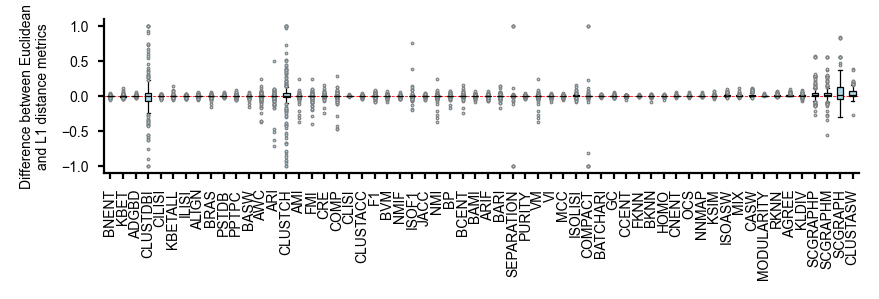

In [55]:
metric_order = (
    pivoted_final.groupby('Metric')['Diff1']
    .median()
    .sort_values(ascending=True)
    .index.tolist()
)

with plt.rc_context({'figure.dpi':200}):
    fig, ax = plt.subplots(figsize=(4.5, 1.6))

    # 2. Use the 'positions' parameter or pass the grouped data manually in order
    # For pandas boxplot, the cleanest way is to pass the sorted categories to positions
    grouped_data = [pivoted_final[pivoted_final['Metric'] == m]['Diff1'] for m in metric_order]

    # 3. Plot using native Matplotlib ax.boxplot to strictly control the ordered data
    ax.boxplot(
        grouped_data,
        labels=metric_order,  # Applies the sorted labels to the x-axis
        patch_artist=True,  
        boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
        medianprops=dict(color="black", linewidth=.45),
        whiskerprops=dict(color="black", linewidth=.45),
        capprops=dict(color="black", linewidth=.45),
        flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
    )
    ax.axhline(0, color='red', linewidth=0.3, linestyle='--', zorder=0)
    # Customizations
    # ax.set_title('Distribution of Differences by Metric (Ordered by Median)', fontsize=14, pad=15)
    # ax.set_xlabel('Metric', fontsize=5)
    ax.tick_params(axis='both', labelsize=5, length=2)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylabel('Difference between Euclidean\nand L1 distance metrics', fontsize=5)
    plt.xticks(rotation=90)
    plt.tight_layout()
    # plt.savefig('../publication_figures/difference_network_centroid_metric.png', dpi=300, bbox_inches='tight')
    plt.show()

In [56]:
summary = pivoted_final.groupby('Metric')['Diff1'].apply(list)
ps = []
for metric in metric_order:
    t = scipy.stats.wilcoxon(summary.loc[metric])
    ps.append(t.pvalue)

ps = scipy.stats.false_discovery_control(ps)
for i, metric in enumerate(metric_order):
    print(metric, ps[i])

BNENT 3.660825438824215e-18
KBET 5.955936921022564e-10
ADGBD 6.1551136925282146e-12
CLUSTDBI 0.3001051193947362
CILISI 4.8176820479549726e-05
KBETALL 5.1065031648077294e-11
ILISI 3.6207519163676125e-07
ALIGN 1.5663609845637078e-08
BRAS 1.803007861527667e-05
PSTDB 0.03976995855465061
PPTPC 2.4467934243443696e-05
BASW 0.0009747302413068737
AWC 0.07952108385718837
ARI 0.04487290127112953
CLUSTCH 0.9542080100689337
AMI 0.04341881322491518
FMI 0.06794835441985346
CRE 0.8442581092444882
COMP 0.4660168616825148
CLISI 1.16357841995815e-06
CLUSTACC 0.49632815089308147
F1 0.8442581092444882
BVM 0.8442581092444882
NMIF 0.2774696438780081
ISOF1 0.9542080100689337
JACC 0.4660168616825148
NMI 0.04487290127112953
BP 0.5187039273976606
BCENT 0.8442581092444882
BAMI 0.8442581092444882
ARIF 0.6835124174373896
BARI 0.6744753639712978
SEPARATION 0.7309181937675185
PURITY 0.49632815089308147
VM 0.04487290127112953
VI 0.14391178154096992
MCC 0.4930820263789666
ISOLISI 0.4509827368006319
COMPACT 0.2229770051

/tmp/ipykernel_3764326/377168986.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


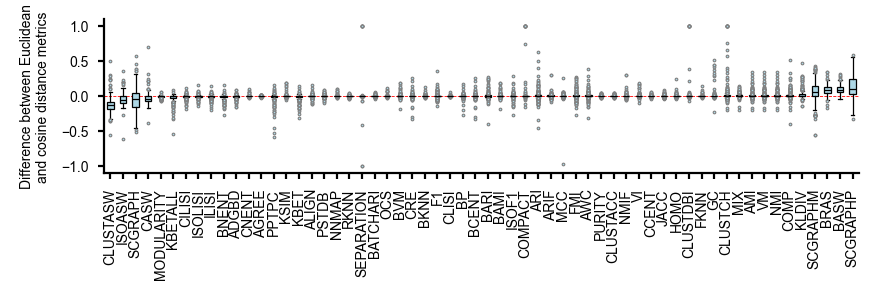

In [57]:
metric_order = (
    pivoted_final.groupby('Metric')['Diff2']
    .median()
    .sort_values(ascending=True)
    .index.tolist()
)

with plt.rc_context({'figure.dpi':200}):
    fig, ax = plt.subplots(figsize=(4.5, 1.6))

    # 2. Use the 'positions' parameter or pass the grouped data manually in order
    # For pandas boxplot, the cleanest way is to pass the sorted categories to positions
    grouped_data = [pivoted_final[pivoted_final['Metric'] == m]['Diff2'] for m in metric_order]

    # 3. Plot using native Matplotlib ax.boxplot to strictly control the ordered data
    ax.boxplot(
        grouped_data,
        labels=metric_order,  # Applies the sorted labels to the x-axis
        patch_artist=True,  
        boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
        medianprops=dict(color="black", linewidth=.45),
        whiskerprops=dict(color="black", linewidth=.45),
        capprops=dict(color="black", linewidth=.45),
        flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
    )
    ax.axhline(0, color='red', linewidth=0.3, linestyle='--', zorder=0)
    # Customizations
    # ax.set_title('Distribution of Differences by Metric (Ordered by Median)', fontsize=14, pad=15)
    # ax.set_xlabel('Metric', fontsize=5)
    ax.tick_params(axis='both', labelsize=5, length=2)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylabel('Difference between Euclidean\nand cosine distance metrics', fontsize=5)
    plt.xticks(rotation=90)
    plt.tight_layout()
    # plt.savefig('../publication_figures/difference_network_centroid_metric.png', dpi=300, bbox_inches='tight')
    plt.show()

In [58]:
summary = pivoted_final.groupby('Metric')['Diff2'].apply(list)
ps = []
for metric in metric_order:
    t = scipy.stats.wilcoxon(summary.loc[metric])
    ps.append(t.pvalue)

ps = scipy.stats.false_discovery_control(ps)
for i, metric in enumerate(metric_order):
    print(metric, ps[i])

CLUSTASW 1.363514622395804e-35
ISOASW 2.0219410447916983e-09
SCGRAPH 1.937516317160699e-05
CASW 2.3623898799761284e-19
MODULARITY 2.571084270328065e-28
KBETALL 5.312733426039485e-17
CILISI 2.787513150813618e-07
ISOLISI 0.031925097220981656
ILISI 1.481990294609903e-07
BNENT 3.771546778460075e-12
ADGBD 7.620414857955988e-11
CNENT 2.174706838777449e-11
AGREE 8.863770070309619e-06
PPTPC 3.628641568100225e-08
KSIM 3.2100117673144442e-06
KBET 2.0575340922215885e-05
ALIGN 0.0012283752487026428
PSTDB 0.000759214398337495
NNMAP 2.8399637536276203e-05
RKNN 0.49845246934270837
SEPARATION 0.01965618628295081
BATCHARI 0.5116430205456797
OCS 0.012667707241799598
BVM 0.8319531368944015
CRE 0.21633584927912997
BKNN 0.062319367590693904
F1 0.39663006921728305
CLISI 0.6219951740862533
BP 0.08305665781135059
BCENT 0.21633584927912997
BARI 0.7552632553496065
BAMI 0.8662253716395724
ISOF1 0.336144186873677
COMPACT 0.0775832421551695
ARI 0.2731342691403271
ARIF 0.08657826588220778
MCC 0.06232307926886686
FM

/tmp/ipykernel_3764326/3407105417.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


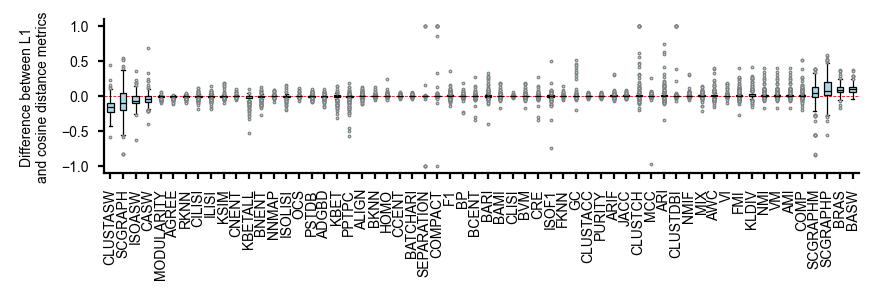

In [59]:
metric_order = (
    pivoted_final.groupby('Metric')['Diff3']
    .median()
    .sort_values(ascending=True)
    .index.tolist()
)

with plt.rc_context({'figure.dpi':200}):
    fig, ax = plt.subplots(figsize=(4.5, 1.6))

    # 2. Use the 'positions' parameter or pass the grouped data manually in order
    # For pandas boxplot, the cleanest way is to pass the sorted categories to positions
    grouped_data = [pivoted_final[pivoted_final['Metric'] == m]['Diff3'] for m in metric_order]

    # 3. Plot using native Matplotlib ax.boxplot to strictly control the ordered data
    ax.boxplot(
        grouped_data,
        labels=metric_order,  # Applies the sorted labels to the x-axis
        patch_artist=True,  
        boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
        medianprops=dict(color="black", linewidth=.45),
        whiskerprops=dict(color="black", linewidth=.45),
        capprops=dict(color="black", linewidth=.45),
        flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
    )
    ax.axhline(0, color='red', linewidth=0.3, linestyle='--', zorder=0)
    # Customizations
    # ax.set_title('Distribution of Differences by Metric (Ordered by Median)', fontsize=14, pad=15)
    # ax.set_xlabel('Metric', fontsize=5)
    ax.tick_params(axis='both', labelsize=5, length=2)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylabel('Difference between L1\nand cosine distance metrics', fontsize=5)
    plt.xticks(rotation=90)
    plt.tight_layout()
    # plt.savefig('../publication_figures/difference_network_centroid_metric.png', dpi=300, bbox_inches='tight')
    plt.show()

In [60]:
summary = pivoted_final.groupby('Metric')['Diff3'].apply(list)
ps = []
for metric in metric_order:
    t = scipy.stats.wilcoxon(summary.loc[metric])
    ps.append(t.pvalue)

ps = scipy.stats.false_discovery_control(ps)
for i, metric in enumerate(metric_order):
    print(metric, ps[i])

CLUSTASW 9.299906079856884e-42
SCGRAPH 1.1612344253075393e-11
ISOASW 4.3644194662516813e-10
CASW 1.1552232996746335e-22
MODULARITY 2.817743685217327e-35
AGREE 1.7202111320655386e-29
RKNN 1.4922345623230832e-17
CILISI 0.0017677907243059917
ILISI 0.0004543559113601416
KSIM 9.761748386292397e-10
CNENT 3.6760601875423105e-16
KBETALL 6.877645421415555e-10
BNENT 1.4619808783480162e-05
NNMAP 4.871527994256589e-14
ISOLISI 0.017776155773246323
OCS 2.4934907437664935e-09
PSTDB 0.002467356015987318
ADGBD 2.5054839588449116e-05
KBET 0.02264119403611959
PPTPC 0.0004867752369834145
ALIGN 0.11036432723540011
BKNN 0.46980840869719603
HOMO 0.8084706693534262
CCENT 0.9288952284634425
BATCHARI 0.04194028972317137
SEPARATION 0.0007659228846644959
COMPACT 0.9994053042818184
F1 0.5069075177366408
BP 0.0455424043850498
BCENT 0.31984775334284277
BARI 0.9758013674385522
BAMI 0.8616159508344877
CLISI 1.4619808783480162e-05
BVM 0.8770151115592804
CRE 0.31984775334284277
ISOF1 0.9579846387004742
FKNN 0.0033643191

### Differences in coefficient of variation across the distance metrics

In [62]:
full_vals.loc[full_vals.index[np.isinf(full_vals['Value'])], 'Value'] = np.nan

In [63]:
cvs = full_vals.pivot(index=['Dataset', 'Integration', 'dist_metric'],
                    columns='Metric', values="Value").groupby(['Dataset', 'dist_metric'])[full_vals.Metric.unique()].apply(
    lambda x: x.std(skipna=True) / x.mean(skipna=True).abs()
).reset_index()

In [64]:
cvs[cvs['dist_metric'] == 'euclidean']['CLUSTDBI'].mean()

np.float64(0.3254449010502842)

In [65]:
import matplotlib.ticker as mticker
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

In [66]:
def plot_cv_metrics(
    df: pd.DataFrame,
    dataset_col: str = "Dataset",
    k_col: str = "dist_metric",
    reference_k = 'euclidean',
    ncols: int = 6,
    figsize_per_cell: tuple = (1.1, .6),
    alpha_levels: tuple = (0.05, 0.01, 0.001),
    color: str = "#378ADD",
    adjustment_method: str = "fdr_bh",
):
    """
    Plot small-multiple bar charts of coefficient of variation (CV) vs neighbor_k,
    averaged across datasets, with Wilcoxon signed-rank significance stars
    compared to a reference k value. P-values are adjusted across all
    metric × k comparisons using the specified multiple-testing correction.
    Error bars show ±1 standard error across datasets.
 
    Parameters
    ----------
    df : pd.DataFrame
        Must contain `dataset_col`, `k_col`, and one column per metric.
    dataset_col : str
        Column name identifying datasets.
    k_col : str
        Column name for neighbor_k values.
    reference_k : int
        The k value to test significance against (default 15).
    ncols : int
        Number of columns in the small-multiple grid.
    figsize_per_cell : tuple
        (width, height) in inches for each subplot cell.
    alpha_levels : tuple
        Thresholds for *, **, *** significance (default 0.05, 0.01, 0.001).
    color : str
        Line/marker color.
    adjustment_method : str
        Multiple-testing correction method passed to statsmodels multipletests
        (e.g. 'fdr_bh', 'bonferroni', 'holm'). Default is 'fdr_bh' (Benjamini-Hochberg).
    """
    metric_cols = ordered_metrics
    k_values = ['euclidean', 'l1', 'cosine']
    n_metrics = len(metric_cols)
    nrows = math.ceil(n_metrics / ncols)
 
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_cell[0] * ncols, figsize_per_cell[1] * nrows),
        constrained_layout=True,
    )
    axes_flat = np.array(axes).flatten()
 
    ref_data = {}
    for metric in metric_cols:
        ref_subset = df[df[k_col] == reference_k][metric].dropna().values
        ref_data[metric] = ref_subset
 
    raw_p_values = {}
    means_per_metric = {}
    stderrs_per_metric = {}
 
    for metric in metric_cols:
        means, stderrs = [], []
        for k in k_values:
            vals = df[df[k_col] == k][metric].dropna().values
            means.append(np.mean(vals))
            stderrs.append(np.std(vals, ddof=1) / np.sqrt(len(vals)))
 
            if k != reference_k and len(vals) >= 2 and len(ref_data[metric]) >= 2:
                ref_vals = ref_data[metric]
                min_len = min(len(vals), len(ref_vals))
                diffs = vals[:min_len] - ref_vals[:min_len]
                if np.any(diffs != 0):
                    _, p = wilcoxon(diffs)
                else:
                    p = 1.0
                raw_p_values[(metric, k)] = p
 
        means_per_metric[metric] = np.array(means)
        stderrs_per_metric[metric] = np.array(stderrs)
 
    keys = list(raw_p_values.keys())
    raw_p_array = np.array([raw_p_values[k] for k in keys])
    _, adj_p_array, _, _ = multipletests(raw_p_array, method=adjustment_method)
    adj_p_values = dict(zip(keys, adj_p_array))
 
    for idx, metric in enumerate(metric_cols):
        ax = axes_flat[idx]
        means = means_per_metric[metric]
        stderrs = stderrs_per_metric[metric]
 
        x = np.arange(len(k_values))
        bars = ax.bar(
            x, means,
            color=color, alpha=0.85,
            width=0.6,
            zorder=3,
        )
 
        # Stars above each bar
        y_range = max(means + stderrs) - min(means - stderrs)
        point_offset = y_range * 0.0001
 
        for i, k in enumerate(k_values):
            if k == reference_k or (metric, k) not in adj_p_values:
                continue
            p = adj_p_values[(metric, k)]
            if p < alpha_levels[2]:
                stars = "***"
            elif p < alpha_levels[1]:
                stars = "**"
            elif p < alpha_levels[0]:
                stars = "*"
            else:
                stars = "ns"
 
            if stars != "ns":
                bar_top = means[i]
                ax.text(x[i], bar_top + point_offset, stars, ha="center", va="bottom",
                        fontsize=9, color="#D85A30", fontweight="bold",
                        clip_on=False)
 
        ax.set_title(metric, fontsize=5, fontweight="medium", pad=6)
        last_row_start = (nrows - 1) * ncols
        is_bottom = last_row_start <= idx < last_row_start + ncols and idx < n_metrics
        is_left = idx % ncols == 0
        if is_bottom:
            ax.set_xlabel("Clustering algorithm", fontsize=5)
        if is_left:
            ax.set_ylabel("CV", fontsize=5)
        ax.set_xticks(x)
        ax.set_xticklabels(k_values)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(0.45)
        ax.spines["bottom"].set_linewidth(0.45)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
#         ax.tick_params(axis='x', labelrotation=45)

        fig.canvas.draw()
#         ticks = ax.yaxis.get_majorticklocs()
#         fmt = "%.2f" if all(round(t, 2) == round(t, 3) for t in ticks) else "%.3f"
#         ax.yaxis.set_major_formatter(mticker.FormatStrFormatter(fmt))
#         ax.grid(axis="y", linewidth=0.4, color="#D3D1C7", zorder=0)
 
    for idx in range(n_metrics, len(axes_flat)):
        axes_flat[idx].set_visible(False)
    return fig

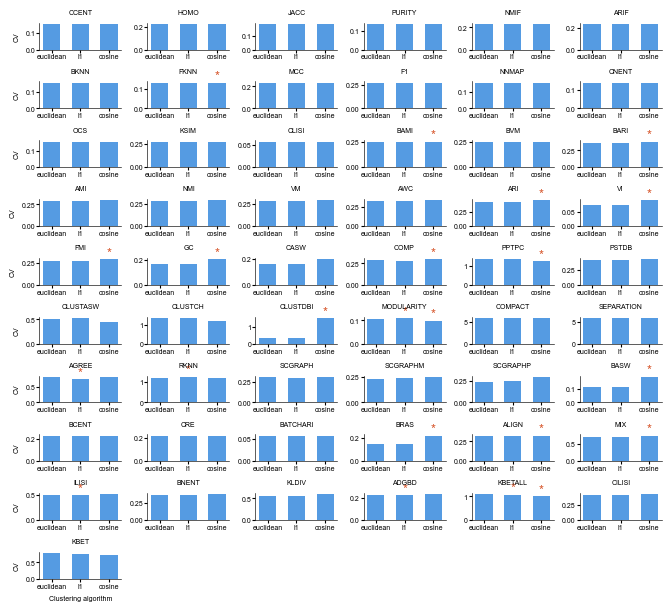

In [67]:
fig = plot_cv_metrics(cvs)
# fig.savefig('../publication_figures/clustering_algorithm_cvs.png', dpi=300, bbox_inches='tight')
plt.show()

## Analyze specific metrics

In [68]:
import scanpy as sc
import anndata as ad

runs = pd.read_csv('../results/spreadsheets/all_integrations.csv')

### Compare Euclidean vs Cosine on SCGRAPH based metrics

In [72]:
df = full_vals[full_vals.Metric == 'SCGRAPHP']  # Replace with one of lines below to select a different metric
# df = full_vals[full_vals.Metric == 'SCGRAPH']
# df = full_vals[full_vals.Metric == 'SCGRAPHM']
df['Dataset'] = df['Dataset'].replace({'human_pbmc_sequencing_techs': 'human_pbmc_seq_techs', 'nph_cerebellum': 'nhp_cerebellum'})

/tmp/ipykernel_3764326/1265291591.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Dataset'] = df['Dataset'].replace({'human_pbmc_sequencing_techs': 'human_pbmc_seq_techs', 'nph_cerebellum': 'nhp_cerebellum'})


In [73]:
# For each integration method, which distance metric in their embeddings space worked the best?

pivoted = df.pivot(index=['Dataset', 'Integration'], columns=['dist_metric'], values='Value').reset_index()
pivoted['best_metric'] = pivoted[['cosine', 'euclidean']].idxmax(axis=1)
# pivoted = pivoted[pivoted['Dataset'] == 'neurips_bmmc']
pivoted = pivoted[~pivoted.Integration.isin(['equidistant-1', 'oneBigBlob-1'])]
best_counts = pivoted.groupby(['Integration', 'best_metric']).size().unstack(fill_value=0)
print(best_counts.to_numpy().sum(0))
best_counts  # Cosine wins vs Euclidean wins

[ 36 228]


best_metric,cosine,euclidean
Integration,,
cca-1,0,8
clear-1,1,7
cyclone-1,0,8
gedi-1,1,7
geneformer-1,0,4
geneptw-1,0,5
harmony-1,0,8
imap-1,0,8
insct-1,2,5


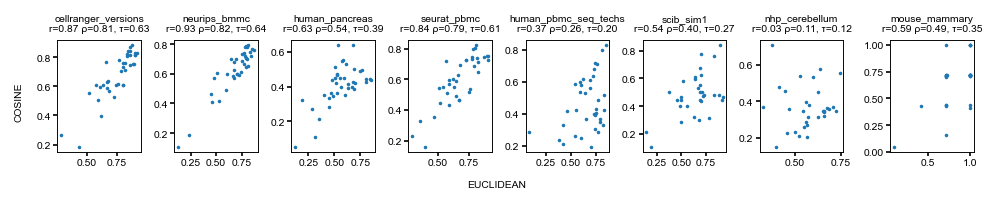

In [76]:
# Plot the correlation between the Euclidean and Cosine distance
metric_a = 'euclidean'
metric_b = 'cosine'

datasets = df['Dataset'].unique()
n_datasets = len(datasets)

n_cols = 8
n_rows = math.ceil(n_datasets / n_cols)

with plt.rc_context({'figure.dpi': 150}):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5, 1.25), constrained_layout=True)

    axes_flat = axes.flatten()

    for i, ds_name in enumerate(datasets):
        ax = axes_flat[i]

        sub = df[(df.dist_metric.isin([metric_a, metric_b])) & (df.Dataset == ds_name)]

        ds_pivoted = sub.pivot(index='Integration', columns='dist_metric', values='Value').dropna(subset=[metric_a, metric_b])

        x = ds_pivoted[metric_a].to_numpy()
        y = ds_pivoted[metric_b].to_numpy()

        ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
        for spine in ax.spines.values():
            spine.set_linewidth(0.45)
        pearson_r = scipy.stats.pearsonr(x, y).statistic
        spearman_rho = scipy.stats.spearmanr(x, y).statistic
        kendall_tau = scipy.stats.kendalltau(x, y).statistic

        ax.scatter(x, y, alpha=1, s=.5, color='tab:blue', zorder=2)
        
#         if "simba-1" in ds_pivoted.index:
#             simba_x = ds_pivoted.loc["simba-1", metric_a]
#             simba_y = ds_pivoted.loc["simba-1", metric_b]
#             ax.scatter(simba_x, simba_y, marker='x', s=4, color='tab:red', zorder=3)
        ax.set_title(f'{ds_name.replace("sequencing", "seq")}\nr={pearson_r:.2f} ρ={spearman_rho:.2f}, τ={kendall_tau:.2f}', fontsize=5, pad=4)

    fig.supxlabel(metric_a.upper(), fontweight='bold', fontsize=5)
    fig.supylabel(metric_b.upper(), fontweight='bold', fontsize=5)

    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].axis('off')
#     plt.savefig('../publication_figures/distance_euc_cosine_corr_highlight_simba.png',dpi=250, bbox_inches='tight')
    plt.savefig(f'../publication_figures/scgraphp_euc_cosine_corr.png', dpi=250, bbox_inches='tight')
    plt.show()

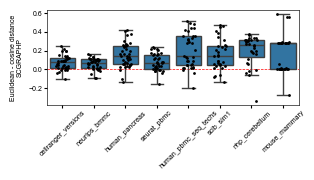

In [77]:
# Plot the overall preference across methods and datasets for Euclidean/Cosine distance
df_filtered = df[df["dist_metric"].isin([metric_a, metric_b])]

df_wide = df_filtered.pivot(
    index=["Dataset", "Integration"], columns="dist_metric", values="Value"
).reset_index()

df_wide['Dataset'] = df_wide["Dataset"].replace("human_pbmc_sequencing_techs", 'human_pbmc_seq_techs')
df_wide["diff"] = df_wide[metric_a] - df_wide[metric_b]

fig, ax = plt.subplots(figsize=(3.25, 1.9))
ax.axhline(0, color="red", linestyle="--", linewidth=0.5, zorder=0)
sns.boxplot(data=df_wide, x="Dataset", y="diff", showfliers=False, order=datasets, ax=ax, color='tab:blue')
sns.stripplot(
    data=df_wide, x="Dataset", y="diff", color="black", order=datasets, alpha=1, jitter=0.2, size=2, ax=ax
)
ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)

plt.xlabel("")
plt.ylabel("Euclidean - cosine distance\nSCGRAPHP", fontsize=5)
plt.xticks(rotation=45)
plt.tight_layout()

# plt.savefig('../publication_figures/scgraphp_euc_cos_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

### Analyze behavior of isolated label metrics

Here, we investigate examples of where isolated label metrics are influenced by the distance metric.

In [78]:
df = full_vals[full_vals.Metric == 'ISOASW']
df['Dataset'] = df['Dataset'].replace({'human_pbmc_sequencing_techs': 'human_pbmc_seq_techs', 'nph_cerebellum': 'nhp_cerebellum'})

/tmp/ipykernel_3764326/881651032.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Dataset'] = df['Dataset'].replace({'human_pbmc_sequencing_techs': 'human_pbmc_seq_techs', 'nph_cerebellum': 'nhp_cerebellum'})


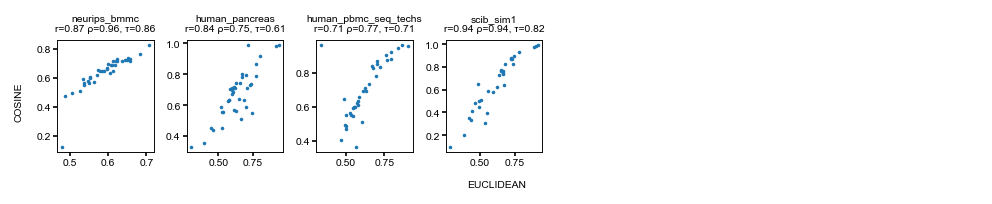

In [81]:
# Plot the correlation between the Euclidean and Cosine distance
metric_a = 'euclidean'
metric_b = 'cosine'

datasets = df['Dataset'].unique()
n_datasets = len(datasets)

n_cols = 8
n_rows = math.ceil(n_datasets / n_cols)

with plt.rc_context({'figure.dpi': 150}):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5, 1.25), constrained_layout=True)

    axes_flat = axes.flatten()

    for i, ds_name in enumerate(datasets):
        ax = axes_flat[i]

        sub = df[(df.dist_metric.isin([metric_a, metric_b])) & (df.Dataset == ds_name)]

        ds_pivoted = sub.pivot(index='Integration', columns='dist_metric', values='Value').dropna(subset=[metric_a, metric_b])

        x = ds_pivoted[metric_a].to_numpy()
        y = ds_pivoted[metric_b].to_numpy()

        ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
        for spine in ax.spines.values():
            spine.set_linewidth(0.45)
        pearson_r = scipy.stats.pearsonr(x, y).statistic
        spearman_rho = scipy.stats.spearmanr(x, y).statistic
        kendall_tau = scipy.stats.kendalltau(x, y).statistic

        ax.scatter(x, y, alpha=1, s=.5, color='tab:blue', zorder=2)
        ax.set_title(f'{ds_name.replace("sequencing", "seq")}\nr={pearson_r:.2f} ρ={spearman_rho:.2f}, τ={kendall_tau:.2f}', fontsize=5, pad=4)

    fig.supxlabel(metric_a.upper(), fontweight='bold', fontsize=5)
    fig.supylabel(metric_b.upper(), fontweight='bold', fontsize=5)

    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].axis('off')

#     plt.savefig('../publication_figures/isoasw_euc_cosine_corr.png')
    plt.show()

Here, we investigate NeurIPS BMMC dataset with Harmony integration to see where the disagreement between distance metrics show up.

We computed clustering with cosine distance and see where the isolated labels show up.

In [84]:
method = 'harmony'
d = runs[runs.name.str.contains('neurips_bmmc') & runs.name.str.contains(method)].iloc[0]['workdir']
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = adata_int.obs.columns[0]
celltype_col = adata_int.obs.columns[1]

adata_int

AnnData object with n_obs × n_vars = 90261 × 13953
    obs: 'batch', 'cell_type', 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0'
    uns: 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0', 'neighbors'
    obsm: 'X_integration', 'X_umap'
    obsp: 'connectivities', 'distances'

In [85]:
adata_int.obs[celltype_col].cat.categories

Index(['B1 B IGKC+', 'B1 B IGKC-', 'CD4+ T CD314+ CD45RA+', 'CD4+ T activated',
       'CD4+ T activated integrinB7+', 'CD4+ T naive', 'CD8+ T CD49f+',
       'CD8+ T CD57+ CD45RA+', 'CD8+ T CD57+ CD45RO+', 'CD8+ T CD69+ CD45RA+',
       'CD8+ T CD69+ CD45RO+', 'CD8+ T TIGIT+ CD45RA+',
       'CD8+ T TIGIT+ CD45RO+', 'CD8+ T naive',
       'CD8+ T naive CD127+ CD26- CD101-', 'CD14+ Mono', 'CD16+ Mono',
       'Erythroblast', 'G/M prog', 'HSC', 'ILC', 'ILC1', 'Lymph prog', 'MAIT',
       'MK/E prog', 'NK', 'NK CD158e1+', 'Naive CD20+ B IGKC+',
       'Naive CD20+ B IGKC-', 'Normoblast', 'Plasma cell IGKC+',
       'Plasma cell IGKC-', 'Plasmablast IGKC+', 'Plasmablast IGKC-',
       'Proerythroblast', 'Reticulocyte', 'T prog cycling', 'T reg',
       'Transitional B', 'cDC1', 'cDC2', 'dnT', 'gdT CD158b+', 'gdT TCRVD2+',
       'pDC'],
      dtype='object')

In [ ]:
# Plot hidden to save space; unused in publication
sc.pl.umap(adata_int, color=[batch_col, celltype_col], ncols=2, wspace=0.4)#, groups=['cDC1', 'T prog cycling', 'CD8+ T naive CD127+ CD26- CD101-'])

In [ ]:
# Plot hidden to save space; unused in publication
sc.pl.umap(adata_int, color='cluster_1.0', legend_loc='on data')

In [88]:
adata_int2 = adata_int.copy()

In [89]:
sc.pp.neighbors(adata_int2, use_rep="X_integration", metric='cosine')
sc.tl.umap(adata_int2)

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Plots hidden to save space; unused in publication
sc.pl.umap(adata_int2, color=[batch_col, celltype_col], ncols=2, wspace=0.4)#,  groups=['cDC1', 'T prog cycling', 'CD8+ T naive CD127+ CD26- CD101-'])

In [96]:
sc.tl.leiden(adata_int2, resolution=2.)

In [ ]:
# Plots hidden to save space; unused in publication
sc.pl.umap(adata_int2, color=['leiden'], legend_loc='on data')

In [98]:
adata_int2.obs[adata_int2.obs[celltype_col] == 'T prog cycling']['leiden'].value_counts()

leiden
22    19
2      3
30     1
7      1
3      0
4      0
1      0
0      0
8      0
9      0
10     0
11     0
12     0
13     0
5      0
6      0
15     0
14     0
18     0
16     0
19     0
20     0
21     0
17     0
23     0
24     0
26     0
25     0
27     0
28     0
29     0
31     0
Name: count, dtype: int64

In [99]:
print(len(adata_int2.obs[adata_int2.obs['leiden'] == '22']))
adata_int2.obs[adata_int2.obs['leiden'] == '22'].cell_type.value_counts(normalize=True)

1027


cell_type
Lymph prog                         0.9113924
CD4+ T activated                   0.0194742
T prog cycling                     0.0185005
T reg                              0.0116845
Transitional B                     0.0107108
MK/E prog                          0.0048685
CD4+ T naive                       0.0038948
cDC2                               0.0038948
HSC                                0.0029211
Naive CD20+ B IGKC+                0.0029211
CD8+ T CD49f+                      0.0019474
G/M prog                           0.0019474
B1 B IGKC+                         0.0009737
CD4+ T activated integrinB7+       0.0009737
NK                                 0.0009737
Plasmablast IGKC+                  0.0009737
Proerythroblast                    0.0009737
CD8+ T naive                       0.0009737
CD8+ T CD57+ CD45RA+               0.0000000
CD4+ T CD314+ CD45RA+              0.0000000
B1 B IGKC-                         0.0000000
CD8+ T TIGIT+ CD45RO+              0.0000000


In [100]:
sklearn.metrics.adjusted_mutual_info_score(adata_int.obs['cluster_2.0'], adata_int2.obs['leiden'])

0.8771518118536813

### Analysis of BRAS using Euclidean vs Cosine distance

In [101]:
df = full_vals[full_vals.Metric == 'BRAS']
df['Dataset'] = df['Dataset'].replace({'human_pbmc_sequencing_techs': 'human_pbmc_seq_techs', 'nph_cerebellum': 'nhp_cerebellum'})

/tmp/ipykernel_3764326/2718040979.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Dataset'] = df['Dataset'].replace({'human_pbmc_sequencing_techs': 'human_pbmc_seq_techs', 'nph_cerebellum': 'nhp_cerebellum'})


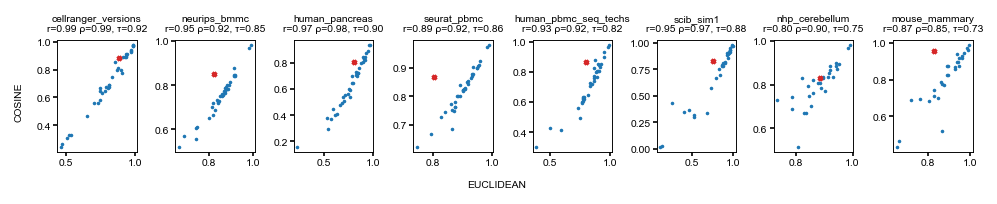

In [102]:
# Plot the correlation between the Euclidean and Cosine distance
metric_a = 'euclidean'
metric_b = 'cosine'

datasets = df['Dataset'].unique()
n_datasets = len(datasets)

n_cols = 8
n_rows = math.ceil(n_datasets / n_cols)

with plt.rc_context({'figure.dpi': 150}):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5, 1.25), constrained_layout=True)

    axes_flat = axes.flatten()

    for i, ds_name in enumerate(datasets):
        ax = axes_flat[i]

        sub = df[(df.dist_metric.isin([metric_a, metric_b])) & (df.Dataset == ds_name)]

        ds_pivoted = sub.pivot(index='Integration', columns='dist_metric', values='Value').dropna(subset=[metric_a, metric_b])

        x = ds_pivoted[metric_a].to_numpy()
        y = ds_pivoted[metric_b].to_numpy()

        ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
        for spine in ax.spines.values():
            spine.set_linewidth(0.45)
        pearson_r = scipy.stats.pearsonr(x, y).statistic
        spearman_rho = scipy.stats.spearmanr(x, y).statistic
        kendall_tau = scipy.stats.kendalltau(x, y).statistic

        ax.scatter(x, y, alpha=1, s=.5, color='tab:blue', zorder=2)
        
        if "simba-1" in ds_pivoted.index:
            simba_x = ds_pivoted.loc["simba-1", metric_a]
            simba_y = ds_pivoted.loc["simba-1", metric_b]
            ax.scatter(simba_x, simba_y, marker='x', s=4, color='tab:red', zorder=3)
        ax.set_title(f'{ds_name.replace("sequencing", "seq")}\nr={pearson_r:.2f} ρ={spearman_rho:.2f}, τ={kendall_tau:.2f}', fontsize=5, pad=4)

    fig.supxlabel(metric_a.upper(), fontweight='bold', fontsize=5)
    fig.supylabel(metric_b.upper(), fontweight='bold', fontsize=5)

    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].axis('off')
#     plt.savefig('../publication_figures/distance_euc_cosine_corr_highlight_simba.png',dpi=250, bbox_inches='tight')
    plt.show()

In [103]:
method = 'simba'
d = runs[runs.name.str.contains('neurips_bmmc') & runs.name.str.contains(method)].iloc[0]['workdir']
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = adata_int.obs.columns[0]
celltype_col = adata_int.obs.columns[1]

adata_int

AnnData object with n_obs × n_vars = 90261 × 13953
    obs: 'batch', 'cell_type', 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0'
    uns: 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0', 'neighbors'
    obsm: 'X_integration', 'X_umap'
    obsp: 'connectivities', 'distances'

In [104]:
norms = np.linalg.norm(adata_int.obsm['X_integration'], axis=1)
adata_int.obs['norms'] = norms

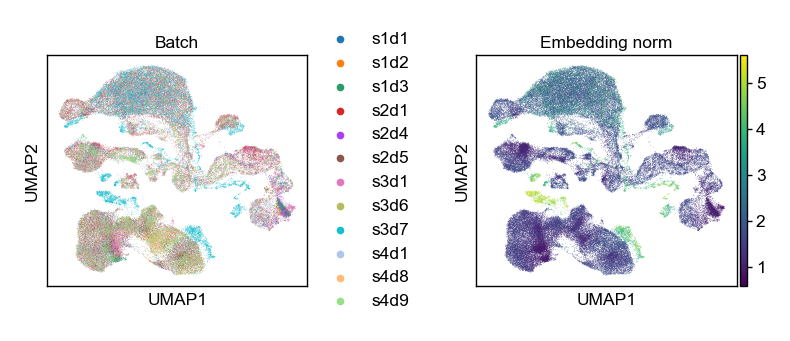

In [106]:
with plt.rc_context({'figure.figsize': (1.2, 1.2), 'figure.dpi': 250, 'legend.markerscale': .2}):
    axs = sc.pl.umap(
        adata_int, 
        color=[batch_col, 'norms'],
        ncols=2, 
        wspace=.5,
        title=[ 'Batch', 'Embedding norm'], 
        legend_fontsize=5,
        size=.1,
        show=False
    )
    frame_thickness = .4
    for ax in axs:
        for spine in ax.spines.values():
            spine.set_linewidth(frame_thickness)
        # Scale down tick label sizes to match smaller figure
        ax.tick_params(labelsize=5)
        # Scale down axis title/label sizes
        ax.xaxis.label.set_size(5)
        ax.yaxis.label.set_size(5)
        ax.title.set_size(5)
        
        ax.set_xlabel(ax.get_xlabel(), labelpad=2)
        ax.set_ylabel(ax.get_ylabel(), labelpad=2)
        
        ax.set_title(ax.get_title(), pad=2, fontsize=5)
        
        cbar = None
        if ax.collections and ax.collections[0].colorbar is not None:
            cbar = ax.collections[0].colorbar

        if cbar is not None:
            cbar.ax.tick_params(labelsize=5, width=0.4, length=1.5, pad=1)
            if cbar.ax.yaxis.get_label():
                cbar.ax.yaxis.label.set_size(5)
            cbar.outline.set_linewidth(0.4)
#     plt.savefig(f'../publication_figures/{method}_{dataset}_umap.png', dpi=300, bbox_inches='tight')
    plt.show()

In [107]:
centroids = []
for b in adata_int.obs[batch_col].unique():
    x = np.mean(adata_int.obsm['X_integration'][adata_int.obs[batch_col] == b],axis=0)
    centroids.append(x)
centroids = np.array(centroids)

In [108]:
euc_dist = scipy.spatial.distance.cdist(centroids, centroids)
df_euc = pd.DataFrame(euc_dist, index=adata_int.obs[batch_col].unique(), columns=adata_int.obs[batch_col].unique())

col_idx = df_euc.columns.get_loc('s3d7')
values_above_diagonal = df_euc.iloc[:col_idx, col_idx]

print(values_above_diagonal.mean())

df_without_s3d7 = df_euc.drop(index='s3d7', columns='s3d7')
print(df_without_s3d7.to_numpy()[np.triu_indices(len(euc_dist)-1, k=1)].mean())

0.42536860630128154
0.1611488860763018


In [109]:
cos_dist = scipy.spatial.distance.cdist(centroids, centroids, metric='cosine')
df_cos = pd.DataFrame(cos_dist, index=adata_int.obs[batch_col].unique(), columns=adata_int.obs[batch_col].unique())

col_idx = df_cos.columns.get_loc('s3d7')
values_above_diagonal = df_cos.iloc[:col_idx, col_idx]

print(values_above_diagonal.mean())

df_without_s3d7 = df_cos.drop(index='s3d7', columns='s3d7')
print(df_without_s3d7.to_numpy()[np.triu_indices(len(cos_dist)-1, k=1)].mean())

0.1614844960946174
0.09976174921409878


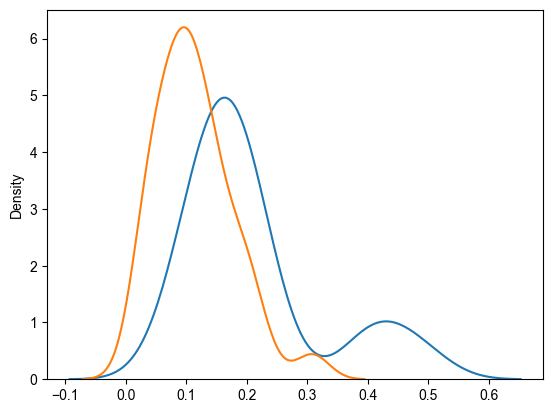

In [110]:
sns.kdeplot(euc_dist[np.triu_indices(len(euc_dist), k=1)])
sns.kdeplot(cos_dist[np.triu_indices(len(cos_dist), k=1)])
plt.show()

In [111]:
sc.pp.neighbors(adata_int, use_rep='X_integration', metric='cosine')
sc.tl.umap(adata_int)

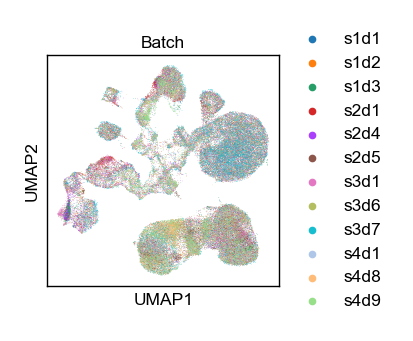

In [112]:
with plt.rc_context({'figure.figsize': (1.2, 1.2), 'figure.dpi': 250, 'legend.markerscale': .2}):
    ax = sc.pl.umap(
        adata_int, 
        color=[batch_col],
        ncols=2, 
        wspace=.5,
        title=['Batch'], 
        legend_fontsize=5,
        size=.1,
        show=False
    )
    frame_thickness = .4
    for spine in ax.spines.values():
        spine.set_linewidth(frame_thickness)
    # Scale down tick label sizes to match smaller figure
    ax.tick_params(labelsize=5)
    # Scale down axis title/label sizes
    ax.xaxis.label.set_size(5)
    ax.yaxis.label.set_size(5)
    ax.title.set_size(5)

    ax.set_xlabel(ax.get_xlabel(), labelpad=2)
    ax.set_ylabel(ax.get_ylabel(), labelpad=2)

    ax.set_title(ax.get_title(), pad=2, fontsize=5)


#     plt.savefig(f'../publication_figures/{method}_{dataset}_cosine_neighbors_umap.png', dpi=300, bbox_inches='tight')
    plt.show()